# DeepSeek-V4.1-Flash-1017 EXL3 3 bpw on 4× CMP 170HX: TP4 P2P matrix and Curtis White's serving stack on our quant

**Licence of the patch stack.** `build/tcmoe1/exl3.py` and `build/v3p1/exl3-1017.patch` modify vllm-exl3 and are **AGPL-3.0** (`build/tcmoe1/vllm-exl3.LICENSE`, with its NOTICE and THIRD_PARTY_NOTICES). Everything else in `build/` keeps its own licence: vLLM files and Morrowmake/Curtis White code Apache-2.0, exllamav3 MIT, Pixel ML scripts Apache-2.0 (this repository's licence).

**Rig.** 4× CMP 170HX (64 GiB, sm_80) on two PLX switches, PCIe Gen2 x16, 140 W cap, host driver NVIDIA 615.71.09 open + PixelML/cmpunlocker. Measured Oct 18 2026, 10:31–11:31 and 16:40–18:27 GMT+7. Credits are in section 8.

In [1]:
# --- Status cell ---
import os
EXPERIMENT = "2026-10-18-deepseek-v4.1-flash-1017-exl3-4card-tp4-curtis-stack-vllm"
RESULTS_DIR = "../results/" + EXPERIMENT
RECEIPTS = RESULTS_DIR + "/receipts"
LIVE = False  # True sends the final request to the endpoint in DSV41_URL (an OpenAI-compatible /v1 base)
ENDPOINT_ENV_VAR = "DSV41_URL"
print("LIVE =", LIVE, "| receipts:", RECEIPTS)

LIVE = False | receipts: ../results/2026-10-18-deepseek-v4.1-flash-1017-exl3-4card-tp4-curtis-stack-vllm/receipts


In [2]:
# --- Helpers ---
import json, csv, statistics, subprocess, sys
from IPython.display import display, Markdown
import matplotlib
import matplotlib.pyplot as plt

def load(*parts):
    p = "/".join(parts)
    return json.load(open(p)) if os.path.exists(p) else None

def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "|".join("---:" if i else "---" for i in range(len(header))) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

PROMPTS = ("coding", "prose", "structured")
def dec(run, p, c):
    d = load(RECEIPTS, run, f"decode-{p}-c{c}.json") or {}
    return d.get("aggregate_tok_s_median") if c > 1 else d.get("tok_s_median")
def acc(run, p):
    return (load(RECEIPTS, run, f"decode-{p}-c1.json") or {}).get("accepted_per_step_median")
def prefill(run):
    d = load(RECEIPTS, run, "prefill.json") or {}
    by = {}
    for r in d.get("results", []):
        by.setdefault(r["target"], []).append(r["prefill_tok_s"])
    return [statistics.median(by[t]) for t in sorted(by)]
def correct(run):
    d = load(RECEIPTS, run, "correctness.json") or {}
    cs = d.get("cases", [])
    return f"{sum(c['pass'] for c in cs)}/{len(cs)}"

INK, INK2, GRID = "#1f2328", "#57606a", "#d0d7de"
S = ["#8c959f", "#0969da", "#1a7f37", "#9a6700", "#cf222e", "#8250df"]
matplotlib.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                            "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
                            "axes.spines.right": False, "font.size": 9})
P2P = [("p2poff", "P2P off (NCCL_P2P_DISABLE=1)"), ("p2psys", "NCCL_P2P_LEVEL=SYS"),
       ("p2pauto", "NCCL default"), ("car128k", "SYS + vLLM custom AR <=128 KiB")]
LADDER = [("tcep", "baseline, EP4"), ("epcoop", "+ coop, EP4"), ("tpcoop", "MoE TP aligned + coop"),
          ("tcfull", "+ TC-MoE v2 + prefill"), ("tcfullhar", "+ host all-reduce"),
          ("tcfullhar-cf-fdo", "+ async, prefix cache, Curtis capture sizes")]
# community-reported (Curtis White, 1017 recipe README @ f5cb5051f0; LibertAI calibrated 2.9 bpw pack, his prompts)
CURTIS = {"c1": (137.1, 96.6, 180.4), "c8": (376, 283, 621), "prefill": (1523, 1531, 1526)}

## 1. TL;DR

- **Measured, P2P matrix (morning, v3p1 image, EP4):** structured c1 **150.1–150.8 tok/s** on three of four arms: the 150 tok/s target is met. Code / prose c1 ≈ 100–105 / 74–75. NCCL P2P (SYS or default) gives **no decode gain** over P2P off; vLLM custom all-reduce over PCIe costs **17–22 %** at c1.
- **Measured, Curtis White's stack on our quant (afternoon, tcmoe1 image):** best arm `tcfullhar-cf-fdo` = c1 **130.2 / 97.2 / 200.8** (code / prose / structured), c8 aggregate **372 / 255 / 671**, prefill 2k / 8k / 32k **1181 / 1688 / 1587**. Against our baseline arm `tcep`: c1 +24 % / +30 % / +33 %, c8 +39 % / +26 % / +48 %.
- **Where the gain comes from (measured, one change per arm):** the coop kernel gives most of the c1 gain; the tensor-core MoE kernels give c8 and prefill; host all-reduce gives code c8 (+26 %).
- **Community-reported (Curtis White, different prompts, LibertAI calibrated pack):** 137.1 / 96.6 / 180.4 c1, 376 / 283 / 621 c8. Our structured cells are higher, code and prose c8 lower. Not a head-to-head.
- **Quality caveat (measured):** every arm passes 5/5 known-answer chat prompts, but the coop / TC arms are **not numerically equal** to the stock path: greedy completions diverge from the baseline after a median of 5 tokens (mean |Δ logprob| 0.036–0.043 against a 0.0045 run-to-run floor), and both host-all-reduce arms answer "The capital of France is" with "750000". Curtis White's `gate0.py` correctness gate did **not** run on our pack (harness mismatch). Treat the fast arms as **untested for quality** beyond the smoke test. The quant is uncalibrated.

In [3]:
pins = {
    "image (P2P matrix, v3p1)": "not on a registry: rebuild with build/v3p1/ (measured local image ID sha256:9de4363a0fb443a2bc1faf51da3e14f10d189016ecd3b477a10905eb3f9abfaf)",
    "image (Curtis stack, tcmoe1)": "not on a registry: rebuild with build/tcmoe1/ (measured local image ID sha256:97d358644223603e25c4f316208eadf82d06444a4e29d00f2778a93734f2f11d)",
    "base of v3p1 (Oct 4 image v3)": "ghcr.io/pixelml/club-170hx@sha256:b8b7a1699bf272855a9b8c8b316f796b3ef917696302baf2a62c856707d69932",
    "build recipes": "results/2026-10-18-deepseek-v4.1-flash-1017-exl3-4card-tp4-curtis-stack-vllm/build/v3p1/ and build/tcmoe1/ (fetch_sources.sh pulls every upstream file at the pins below and checks git blob hashes)",
    "TC-MoE source": "CurtisAccelerate/DeepSeekv41-Flash-EXL3-TC-MoE @ cd83ade14c43a42babad39895d75bdd0e3453d49 (Apache-2.0)",
    "host all-reduce source": "Morrowmake/vllm-cmp170hx @ 18305948acba3f4c4d912cdd56f2202d2ebd94e8 (Apache-2.0)",
    "vllm-exl3 (coop route, aligned TP)": "vcruz305/vllm-exl3 @ 2a740a3773601c994072295fde45738ef8cea55e (PRs #27 #36 #40, AGPL-3.0)",
    "exllamav3 (coop kernel)": "turboderp-org/exllamav3 @ d3739fd393337b1ff4d6c2a342b12f0c87a9592f (v1.5.3, MIT)",
    "quant": "PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw @ 3d095b724ed4f3abb519cc1cda64c290a0e0b0c5 (routed experts EXL3 K3 MUL1, uncalibrated; MIT)",
    "base model + Engram shards 47-48": "deepseek-ai/DeepSeek-V4.1-Flash-1017 @ 1bae0e1088993b9b82de08f59de5be5a34e42170 (MIT); Engram converted to int4 with build/v3p1/engram_int4.py",
    "quant script": "sfxnz/DeepSeek-V4.1-Flash-EXL3-vLLM-2x-DGX-Spark @ 3de914682d0880c8e478712a60ada930339c22e4, exllamav3 @ 5be886578ec80324c2c715269387be2058724b6e",
    "driver": "NVIDIA 615.71.09 open + PixelML/cmpunlocker tag cmp170hx-plx-p2p-2026-10-02 = 6ca4da72f078553d37089ee741cd128aa7804504 (64 GiB, 74 SMs, BAR1 P2P); RegistryDwords RMForceStaticBar1=1;RMPcieP2PType=1;RmForceEnableGen2=1;RMPcieLinkSpeed=0x1",
    "host": "Proxmox VE 9.2, kernel 7.0.2-6-pve, 2x Xeon E5-2686 v4, 251 GiB; privileged LXC bench container sharing the host driver (GPUs by CDI)",
    "topology": "two PLX switches: cards 0-1 PIX, cards 2-3 PIX, cross pairs PHB; PCIe Gen2 x16 on all four",
    "power": "nvidia-smi -pm 1 && nvidia-smi -pl 140 (all arms)",
    "serve args": "receipts/<arm>/launch.txt (complete docker run line) + build/serve/launch-1017.sh / launch-curtis-1017.sh",
}
for k, v in pins.items():
    print(f"{k:36s} {v}")

image (P2P matrix, v3p1)             not on a registry: rebuild with build/v3p1/ (measured local image ID sha256:9de4363a0fb443a2bc1faf51da3e14f10d189016ecd3b477a10905eb3f9abfaf)
image (Curtis stack, tcmoe1)         not on a registry: rebuild with build/tcmoe1/ (measured local image ID sha256:97d358644223603e25c4f316208eadf82d06444a4e29d00f2778a93734f2f11d)
base of v3p1 (Oct 4 image v3)        ghcr.io/pixelml/club-170hx@sha256:b8b7a1699bf272855a9b8c8b316f796b3ef917696302baf2a62c856707d69932
build recipes                        results/2026-10-18-deepseek-v4.1-flash-1017-exl3-4card-tp4-curtis-stack-vllm/build/v3p1/ and build/tcmoe1/ (fetch_sources.sh pulls every upstream file at the pins below and checks git blob hashes)
TC-MoE source                        CurtisAccelerate/DeepSeekv41-Flash-EXL3-TC-MoE @ cd83ade14c43a42babad39895d75bdd0e3453d49 (Apache-2.0)
host all-reduce source               Morrowmake/vllm-cmp170hx @ 18305948acba3f4c4d912cdd56f2202d2ebd94e8 (Apache-2.0)
vllm-exl3 (c

## 2. TP4 P2P matrix (measured, v3p1 image, EP4, DSpark k=5)

One boot per arm, thinking off, T=0, median of 3. Decode = `bench_decode.py` per-stream tok/s after the first token (c1) and aggregate tok/s across 8 streams (c8). Prefill = `bench_long_1017.py`, novel text, prompt tokens / time to first token.

In [4]:
rows = []
for run, lab in P2P:
    pf = prefill(run)
    rows.append([lab] + [f"{dec(run, p, 1):.1f}" for p in PROMPTS] + [f"{dec(run, p, 8):.0f}" for p in PROMPTS]
                + [" / ".join(f"{x:.0f}" for x in pf), f"{acc(run, 'coding'):.2f}", correct(run)])
table(["arm", "code c1", "prose c1", "struct c1", "code c8 agg", "prose c8 agg", "struct c8 agg",
       "prefill 2k / 8k / 32k", "accept/step code c1", "known answers"], rows)

| arm | code c1 | prose c1 | struct c1 | code c8 agg | prose c8 agg | struct c8 agg | prefill 2k / 8k / 32k | accept/step code c1 | known answers |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| P2P off (NCCL_P2P_DISABLE=1) | 104.4 | 75.4 | 150.1 | 273 | 201 | 454 | 1036 / 1553 / 1458 | 3.35 | 5/5 |
| NCCL_P2P_LEVEL=SYS | 100.6 | 75.3 | 150.0 | 260 | 203 | 454 | 806 / 1448 / 1381 | 3.17 | 5/5 |
| NCCL default | 105.2 | 74.2 | 150.8 | 264 | 196 | 450 | 980 / 1453 / 1373 | 3.35 | 5/5 |
| SYS + vLLM custom AR <=128 KiB | 86.6 | 58.2 | 118.9 | 270 | 206 | 456 | 1006 / 1423 / 1373 | 3.52 | 5/5 |

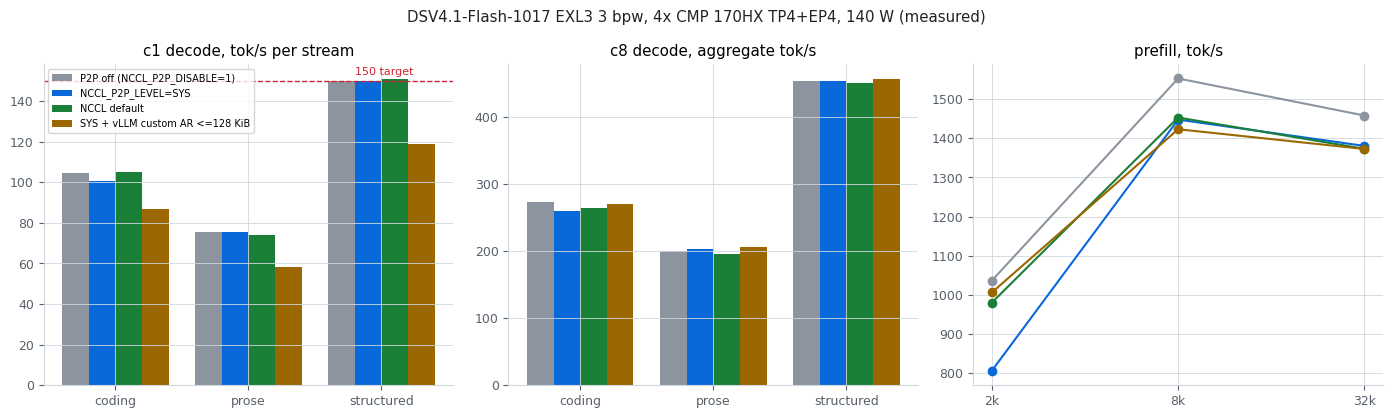

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
w = 0.2
for i, (run, lab) in enumerate(P2P):
    for ax, c, title in ((axes[0], 1, "c1 decode, tok/s per stream"), (axes[1], 8, "c8 decode, aggregate tok/s")):
        ax.bar([j + i * w for j in range(3)], [dec(run, p, c) for p in PROMPTS], w, color=S[i], label=lab)
        ax.set_title(title); ax.set_xticks([j + 1.5 * w for j in range(3)], PROMPTS)
    axes[2].plot(["2k", "8k", "32k"], prefill(run), marker="o", color=S[i], label=lab)
axes[0].axhline(150, color=S[4], lw=1, ls="--"); axes[0].text(2.1, 153, "150 target", color=S[4], fontsize=8)
axes[2].set_title("prefill, tok/s"); axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle("DSV4.1-Flash-1017 EXL3 3 bpw, 4x CMP 170HX TP4+EP4, 140 W (measured)", color=INK)
fig.tight_layout(); plt.show()

- **Measured:** P2P on (SYS or NCCL default) and P2P off give the same decode within 4 %. The bus is not the c1 limit here.
- **Measured:** vLLM custom all-reduce over PCIe P2P (`car128k`) costs 17 % code, 23 % prose, 21 % structured at c1, with c8 equal. Same direction as Oct 4.
- **Measured:** structured acceptance is ~5 tokens per step of 5 (the prompt counts 1 to 200), so the structured cell measures the draft path at its best. Code and prose are the realistic cells.

## 3. Curtis White's serving stack on our quant (measured, tcmoe1 image)

Each arm adds one change. Same prompts, tools and receipts format as section 2, util 0.95 for the MoE-TP arms (0.92 does not fit, section 5). Curtis White's row is **community-reported**: his prompts, LibertAI's calibrated 2.9 bpw expert pack, a FP8 Engram pin, and DSpark on the V1 runner.

In [6]:
rows = []
for run, lab in LADDER:
    pf = prefill(run)
    rows.append([f"`{run}`: {lab}"] + [f"{dec(run, p, 1):.1f}" for p in PROMPTS] + [f"{dec(run, p, 8):.0f}" for p in PROMPTS]
                + [" / ".join(f"{x:.0f}" for x in pf), correct(run)])
rows.append(["Curtis White 1017 (community-reported)"] + [f"{x:.1f}" for x in CURTIS["c1"]] + [str(x) for x in CURTIS["c8"]]
            + [" / ".join(str(x) for x in CURTIS["prefill"]) + " (2k / 8k / 32k)", "-"])
table(["arm", "code c1", "prose c1", "struct c1", "code c8 agg", "prose c8 agg", "struct c8 agg", "prefill 2k / 8k / 32k", "known answers"], rows)

| arm | code c1 | prose c1 | struct c1 | code c8 agg | prose c8 agg | struct c8 agg | prefill 2k / 8k / 32k | known answers |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| `tcep`: baseline, EP4 | 105.4 | 74.5 | 150.8 | 267 | 203 | 454 | 1047 / 1555 / 1459 | 5/5 |
| `epcoop`: + coop, EP4 | 127.1 | 97.5 | 182.5 | 271 | 203 | 456 | 1041 / 1555 / 1460 | 5/5 |
| `tpcoop`: MoE TP aligned + coop | 125.6 | 92.1 | 190.7 | 211 | 184 | 502 | 671 / 972 / 946 | 5/5 |
| `tcfull`: + TC-MoE v2 + prefill | 130.4 | 92.0 | 190.7 | 284 | 248 | 642 | 1306 / 1685 / 1592 | 5/5 |
| `tcfullhar`: + host all-reduce | 130.6 | 96.8 | 200.5 | 359 | 249 | 648 | 1302 / 1683 / 1586 | 5/5 |
| `tcfullhar-cf-fdo`: + async, prefix cache, Curtis capture sizes | 130.2 | 97.2 | 200.8 | 372 | 255 | 671 | 1181 / 1688 / 1587 | 5/5 |
| Curtis White 1017 (community-reported) | 137.1 | 96.6 | 180.4 | 376 | 283 | 621 | 1523 / 1531 / 1526 (2k / 8k / 32k) | - |

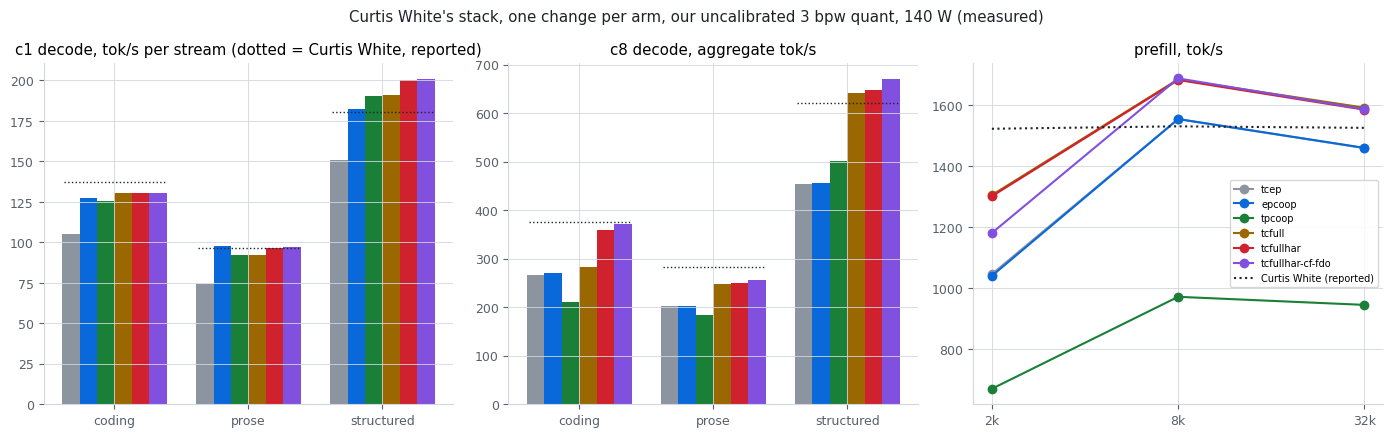

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
w = 0.13
for i, (run, lab) in enumerate(LADDER):
    for ax, c in ((axes[0], 1), (axes[1], 8)):
        ax.bar([j + i * w for j in range(3)], [dec(run, p, c) for p in PROMPTS], w, color=(S + ["#24292f"])[i], label=run)
    axes[2].plot(["2k", "8k", "32k"], prefill(run), marker="o", color=(S + ["#24292f"])[i], label=run)
for ax, key in ((axes[0], "c1"), (axes[1], "c8")):
    for j, v in enumerate(CURTIS[key]):
        ax.plot([j - 0.05, j + 6 * w - 0.08], [v, v], color=INK, lw=1, ls=":")
    ax.set_xticks([j + 2.5 * w for j in range(3)], PROMPTS)
axes[2].plot(["2k", "8k", "32k"], CURTIS["prefill"], ls=":", color=INK, label="Curtis White (reported)")
axes[0].set_title("c1 decode, tok/s per stream (dotted = Curtis White, reported)")
axes[1].set_title("c8 decode, aggregate tok/s"); axes[2].set_title("prefill, tok/s")
axes[2].legend(fontsize=7)
fig.suptitle("Curtis White's stack, one change per arm, our uncalibrated 3 bpw quant, 140 W (measured)", color=INK)
fig.tight_layout(); plt.show()

In [8]:
# switches that took: launch line (tcmoe-lines.txt) + boot-log lines (switch-lines.txt, where present)
rows = []
for run, lab in LADDER:
    t = open(f"{RECEIPTS}/{run}/tcmoe-lines.txt").read()
    p = f"{RECEIPTS}/{run}/switch-lines.txt"
    s = open(p).read() if os.path.exists(p) else ""
    rows.append([run, "on" if "COOP=1" in t else "off", "on" if "aligned MoE TP" in s else "off",
                 "on" if "v2=on prefill=on" in s else "off", "on" if "host-shm all-reduce" in s and ": ON" in s else "off"])
table(["arm", "coop (launch)", "aligned MoE TP (boot log)", "TC MoE v2 + prefill (boot log)", "host all-reduce (boot log)"], rows)

| arm | coop (launch) | aligned MoE TP (boot log) | TC MoE v2 + prefill (boot log) | host all-reduce (boot log) |
|---|---:|---:|---:|---:|
| tcep | off | off | off | off |
| epcoop | on | off | off | off |
| tpcoop | on | on | off | off |
| tcfull | on | on | on | off |
| tcfullhar | on | on | on | on |
| tcfullhar-cf-fdo | on | on | on | on |

## 4. Quality (measured: smoke and greedy agreement only)

- Known answers (5 chat prompts, greedy: `17*23`, Canberra, 215 minutes, `is_prime(97)`, `TNAHPELE`): **5/5 on all 10 arms**.
- Greedy agreement against `p2poff` on 12 raw-completion prompts × 64 tokens (`build/bench/qcmp.py`, top-5 logprobs in `qref.json`):

In [9]:
QC = ["p2psys", "p2pauto", "car128k"] + [r for r, _ in LADDER]
rows = []
for a in QC:
    out = subprocess.run([sys.executable, f"{RESULTS_DIR}/build/bench/qcmp.py", f"{RECEIPTS}/p2poff/qref.json", f"{RECEIPTS}/{a}/qref.json"],
                         capture_output=True, text=True).stdout.strip()
    rows.append([a, out])
table(["arm vs p2poff", "qcmp.py"], rows)
q = {a: load(RECEIPTS, a, "qref.json") for a in ("p2poff", "tcfull", "tcfullhar", "tcfullhar-cf-fdo")}
table(["arm", "'The capital of France is' (greedy, first 60 chars)"], [[a, repr(v[0]["text"][:60])] for a, v in q.items()])

| arm vs p2poff | qcmp.py |
|---|---:|
| p2psys | identical completions 11/12 | tokens before first divergence: median 64 min 41 | mean |dlogprob| on shared prefix 0.0045 |
| p2pauto | identical completions 11/12 | tokens before first divergence: median 64 min 41 | mean |dlogprob| on shared prefix 0.0053 |
| car128k | identical completions 4/12 | tokens before first divergence: median 13 min 1 | mean |dlogprob| on shared prefix 0.0136 |
| tcep | identical completions 10/12 | tokens before first divergence: median 64 min 3 | mean |dlogprob| on shared prefix 0.0044 |
| epcoop | identical completions 1/12 | tokens before first divergence: median 5 min 2 | mean |dlogprob| on shared prefix 0.0390 |
| tpcoop | identical completions 2/12 | tokens before first divergence: median 5 min 0 | mean |dlogprob| on shared prefix 0.0363 |
| tcfull | identical completions 2/12 | tokens before first divergence: median 5 min 0 | mean |dlogprob| on shared prefix 0.0363 |
| tcfullhar | identical completions 1/12 | tokens before first divergence: median 5 min 0 | mean |dlogprob| on shared prefix 0.0427 |
| tcfullhar-cf-fdo | identical completions 1/12 | tokens before first divergence: median 5 min 0 | mean |dlogprob| on shared prefix 0.0427 |

| arm | 'The capital of France is' (greedy, first 60 chars) |
|---|---:|
| p2poff | ' Paris. The population of France is 67 million. The capital ' |
| tcfull | ' Paris. The population of France is 67 million. The capital ' |
| tcfullhar | ' 750000. The population of France is 750000. The population ' |
| tcfullhar-cf-fdo | ' 750000. The population of France is 750000. The population ' |

- **Measured:** the stock-path arms agree with `p2poff` to the run-to-run floor (11/12 identical, mean |Δ logprob| ≈ 0.005). `car128k` drifts (0.014), as on Oct 4.
- **Measured:** every coop arm changes greedy text early (median first divergence 5 tokens, |Δ logprob| ≈ 0.04, 8–9× the floor). Most completions stay plausible; the two host-all-reduce arms give a wrong fact on one prompt of 12.
- **Inferred:** the coop kernel is the source of the change (it first appears in `epcoop`, EP4, before MoE TP, TC or host all-reduce). Curtis White reports FP64 errors 0.64–1.00× the stock path on his pack; we could not run that gate on ours. Needs a PPL/KL run before any of these arms is served.

## 5. What did not work (measured failures, receipts kept)

| receipt | change | result | fix used |
|---|---|---|---|
| `fail-engram-disk-tier` | int4 Engram with the default disk tier | load assert: disk tier reads FP8 only (`engram_disk.py`) | `DSV41_ENGRAM_DISK=0` (int4 pinned in RAM) |
| `fail-bias-vl-model` | 1017 checkpoint on the image's loader | `KeyError: layers.0.ffn.gate.bias_vl` (1017 adds an image-token router bias) | skip `.bias_vl` when absent, `serve/patch/model.py.patch` (exact for `--language-model-only`) |
| `fail-bias-vl-dspark` | same, DSpark draft loader | same `KeyError` in `dspark.py` | `serve/patch/dspark.py.patch` |
| `fail-fat32-capture` | `VLLM_EXL3_FAT_THRESHOLD=32` with capture sizes up to 48 | `cudaErrorStreamCaptureUnsupported`: a host `.item()` sync above the threshold | threshold 48 (= max capture size) |
| `fail-tpcoop-util092` | MoE TP at `--gpu-memory-utilization 0.92` | `Available KV cache memory: -0.87 GiB` | util 0.95 (no Xid at 0.95) |
| `fail-coop-piecewise` | Curtis White's `FULL_AND_PIECEWISE` graphs | "piecewise CUDA graphs unavailable, model is not torch-compiled" on the V2 runner | `FULL_DECODE_ONLY`; his V1-runner DSpark (`DSV41_DSPARK_V1`) is not public |

Also: Curtis White's `gate0.py` stopped at `AttributeError: 'Module' object has no attribute 'w13_trellis'` (it builds layers through a plugin API our `exl3.py` does not have), so the gate did not run. Earlier containers left a zombie process at teardown; `docker run --init` fixed it.

## 6. Not covered (untested)

- The 2× DGX Spark run of the same quant (staged, not served).
- PPL / KL against the source model, and the LibertAI 2.9 bpw pack on our stack.
- FP8 Engram pin (about 190 GB host RAM; this host has 251 GiB), 262k context, HBM NDIV lock, EXL3 arena cache, power caps other than 140 W.

In [10]:
def telem(run):
    t, w = [], []
    for r in list(csv.reader(open(f"{RECEIPTS}/{run}/telemetry.csv")))[1:]:
        try:
            t.append(float(r[2])); w.append(float(r[3].replace("W", "")))
        except (ValueError, IndexError):
            pass
    return (max(t) if t else None, statistics.mean(w) if w else None, max(w) if w else None)
rows = [[r] + [f"{x:.0f}" if x is not None else "-" for x in telem(r)] for r, _ in P2P + LADDER]
table(["arm", "max core temp °C", "mean power W (2 s samples, all cards)", "max instantaneous sample W"], rows)

| arm | max core temp °C | mean power W (2 s samples, all cards) | max instantaneous sample W |
|---|---:|---:|---:|
| p2poff | 75 | 120 | 248 |
| p2psys | 75 | 120 | 197 |
| p2pauto | 75 | 116 | 200 |
| car128k | 75 | 116 | 207 |
| tcep | 76 | 118 | 236 |
| epcoop | 76 | 119 | 191 |
| tpcoop | 76 | 122 | 190 |
| tcfull | 77 | 124 | 191 |
| tcfullhar | 77 | 124 | 193 |
| tcfullhar-cf-fdo | 77 | 126 | 230 |

- **Measured:** the cap is 140 W on all four cards (`nvidia-smi-start.csv`). About 8 % of 2 s `power.draw` samples read above 145 W; in those samples the SM clock is down (for example 1005 MHz at 248 W), so these are instantaneous readings while the limiter acts, not a higher sustained draw. Core temperature stayed at or below 77 °C.

## 7. Reproduce

Hardware: 4 × CMP 170HX with the 64 GiB / 74-SM driver and BAR1 P2P, about 330 GB of disk, ≥ 180 GiB host RAM (int4 Engram pin ≈ 103 GiB + runtime).

```bash
# driver: PixelML/cmpunlocker tag cmp170hx-plx-p2p-2026-10-02 (6ca4da72f078553d37089ee741cd128aa7804504), NVIDIA 615.71.09 open; see that repo's README
nvidia-smi -pm 1 && nvidia-smi -pl 140
docker build -t dsv41-1017-exl3:sm80-v3p1 build/v3p1
build/tcmoe1/fetch_sources.sh && docker build --build-arg BASE=dsv41-1017-exl3:sm80-v3p1 -t dsv41-1017-exl3:sm80-tcmoe1 build/tcmoe1
hf download PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw --revision 3d095b724ed4f3abb519cc1cda64c290a0e0b0c5 --local-dir <models>/dsv41-1017/pack
hf download deepseek-ai/DeepSeek-V4.1-Flash-1017 --revision 1bae0e1088993b9b82de08f59de5be5a34e42170 \
  model-00047-of-00048.safetensors model-00048-of-00048.safetensors --local-dir <models>/dsv41-1017/engram-fp8
for s in 47 48; do python3 -I build/v3p1/engram_int4.py <models>/dsv41-1017/engram-fp8/model-000$s-of-00048.safetensors \
  <models>/dsv41-1017/engram-int4/model-000$s-of-00048.safetensors --workers 16; done
python3 -I build/v3p1/prepare_1017.py --source <models>/dsv41-1017/pack --engram <models>/dsv41-1017/engram-int4 --out <models>/dsv41-1017/view
# serve scripts expect /models/dsv41-1017 and the patch files under /root/dsv41-tp4/ (edit the -v lines for your paths)
IMG=dsv41-1017-exl3:sm80-v3p1 build/serve/matrix-1017.sh p2poff p2psys p2pauto car128k
IMG=dsv41-1017-exl3:sm80-tcmoe1 GPU_UTIL=0.95 build/serve/matrix-curtis-1017.sh tcep epcoop tpcoop tcfull tcfullhar tcfullhar-cf-fdo
```

Each arm writes the files under `receipts/<arm>/`. Comments in `build/serve/` were generalised for publication; the code lines are the ones that ran (`pins.json` hashes refer to the unedited files).

## Try your own prompt

Edit `PROMPT`. With `LIVE = False`, the cell prints the recorded single-user decode summary of the fastest arm.

In [11]:
PROMPT = "Explain PCIe peer-to-peer in three sentences."
if LIVE:
    import urllib.request
    url = os.environ[ENDPOINT_ENV_VAR]
    body = {"model": "deepseek-v4.1-flash", "messages": [{"role": "user", "content": PROMPT}], "max_tokens": 400,
            "temperature": 0, "chat_template_kwargs": {"enable_thinking": False}}
    req = urllib.request.Request(url + "/chat/completions", json.dumps(body).encode(), {"Content-Type": "application/json"})
    resp = json.load(urllib.request.urlopen(req, timeout=600))
    m = resp["choices"][0]["message"]
    print(m.get("content")); print(resp["usage"])
else:
    d = load(RECEIPTS, "tcfullhar-cf-fdo", "decode-prose-c1.json")
    print({k: d[k] for k in ("phase", "tok_s_median", "accepted_per_step_median", "completion_tokens_median")})

{'phase': 'prose-c1', 'tok_s_median': 97.15334783748516, 'accepted_per_step_median': 2.061, 'completion_tokens_median': 400.0}


## 8. Credits

- **Serving stack replicated here:** Curtis White ([@CurtisAccelerate](https://github.com/CurtisAccelerate)) authored the tensor-core EXL3 MoE port for DeepSeek V4.1 (row dispatch coop 1–42 / `moe_out_v2` 43–64 / `moe_out_prefill` 65–2048, the shared 540.4 MiB workspace, the EXL3 hook, `gate0.py`): [DeepSeekv41-Flash-EXL3-TC-MoE @ cd83ade14c43a42babad39895d75bdd0e3453d49](https://github.com/CurtisAccelerate/DeepSeekv41-Flash-EXL3-TC-MoE/tree/cd83ade14c43a42babad39895d75bdd0e3453d49) (Apache-2.0). His 1017 serve flags and numbers: [DeepSeekv41-Flash-1017-EXL3-CMP170HX @ f5cb5051f0](https://github.com/CurtisAccelerate/DeepSeekv41-Flash-1017-EXL3-CMP170HX/tree/f5cb5051f0) (that repository has no licence file; we use its flags as facts and copy none of its files).
- **Tensor-core EXL3 MoE kernels and host-staged all-reduce:** Morrowmake ([@Morrowmake](https://github.com/Morrowmake)), [vllm-cmp170hx @ 18305948acba3f4c4d912cdd56f2202d2ebd94e8](https://github.com/Morrowmake/vllm-cmp170hx/tree/18305948acba3f4c4d912cdd56f2202d2ebd94e8) (Apache-2.0).
- **Coop route and aligned MoE TP:** vllm-exl3 by Victor Cruz ([@vcruz305](https://github.com/vcruz305)), AGPL-3.0 — [PR #27](https://github.com/vcruz305/vllm-exl3/pull/27) coop route by @kaka86mm, [PR #36](https://github.com/vcruz305/vllm-exl3/pull/36) and [PR #40](https://github.com/vcruz305/vllm-exl3/pull/40) aligned uneven TP split and per-layer rotation by @fattchris, all in [main @ 2a740a3773601c994072295fde45738ef8cea55e](https://github.com/vcruz305/vllm-exl3/tree/2a740a3773601c994072295fde45738ef8cea55e).
- **EXL3 format, `exl3_moe_coop` kernel:** turboderp ([@turboderp](https://github.com/turboderp)), [exllamav3 @ d3739fd393337b1ff4d6c2a342b12f0c87a9592f](https://github.com/turboderp-org/exllamav3/tree/d3739fd393337b1ff4d6c2a342b12f0c87a9592f) (v1.5.3, MIT).
- **Base serving image lineage:** 0xSero ([@0xSero](https://github.com/0xSero)), [dsv41-flash-offload @ 2e9da5ecdab37c232c2da887e25c33a99da738d3](https://github.com/0xSero/dsv41-flash-offload/tree/2e9da5ecdab37c232c2da887e25c33a99da738d3) (MIT), with the Pixel ML TP4/EP4 + int4 Engram build in [`results/2026-10-03-deepseek-v4.1-flash-exl3-4card-tp4ep4-dspark-vllm/build/`](../results/2026-10-03-deepseek-v4.1-flash-exl3-4card-tp4ep4-dspark-vllm/).
- **Quant script:** sfxnz ([@sfxnz](https://github.com/sfxnz)), `tools/quantize_experts_exl3.py` in [DeepSeek-V4.1-Flash-EXL3-vLLM-2x-DGX-Spark @ 3de914682d0880c8e478712a60ada930339c22e4](https://github.com/sfxnz/DeepSeek-V4.1-Flash-EXL3-vLLM-2x-DGX-Spark/tree/3de914682d0880c8e478712a60ada930339c22e4) (MIT).
- **Model:** DeepSeek-AI ([@deepseek-ai](https://huggingface.co/deepseek-ai)), [DeepSeek-V4.1-Flash-1017 @ 1bae0e1088993b9b82de08f59de5be5a34e42170](https://huggingface.co/deepseek-ai/DeepSeek-V4.1-Flash-1017/tree/1bae0e1088993b9b82de08f59de5be5a34e42170) (MIT). Quant: [PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw @ 3d095b724ed4f3abb519cc1cda64c290a0e0b0c5](https://huggingface.co/PixelML/DeepSeek-V4.1-Flash-1017-EXL3-3bpw/tree/3d095b724ed4f3abb519cc1cda64c290a0e0b0c5).
- **Benchmark prompts:** MiaAI-Lab ([@MiaAI-Lab](https://github.com/MiaAI-Lab)) decode prompts, as in the Oct 3 notebook.